In [1]:
from langchain_community.document_loaders import TextLoader, DirectoryLoader
from langchain_openai import OpenAIEmbeddings, ChatOpenAI 
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document 
from langchain_text_splitters import RecursiveCharacterTextSplitter 
from langchain_chroma import Chroma 
from pathlib import Path 
from dotenv import load_dotenv 

/var/folders/_r/sndd4_s924d6z4fgsvt_v31r0000gn/T/ipykernel_50623/1090953607.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader, DirectoryLoader


In [2]:
# 1. Load the api keys 

load_dotenv() 

True

In [3]:
# 2. Create the LLM and Embedding model 

llm = ChatOpenAI(model = 'gpt-5-mini')
embedder = OpenAIEmbeddings(model = 'text-embedding-3-small', 
                            dimensions= 1024) # defaul 1536 

In [4]:
# 3. Load the documents from source 

loader = DirectoryLoader(path = Path("./cleaned-transcripts/").as_posix(), 
                         loader_cls= TextLoader, 
                         show_progress= True )


docs = loader.load()

100%|██████████| 6/6 [00:00<00:00, 1397.95it/s]


In [5]:
docs[1].page_content[:1000]

"WEBVTT\nHi everyone good evening guys a quick check am audible visible is my one note visible great\nwait for another 5 minutes so that everyone can join\ntill then if you have any questions you can ask me\nwithout quick questions\nall good\nyou are practicing together\nyou have coded the application by yourself\nok first task\nfollowing\nright\nthis is what is required from you\njust follow along\nand if you don't understand any part then do watch the recordings\nbecause LLM ops is a field where every class is connected to each other\nmaybe what you are studying today will be useful again after 10 classes\ngood evening\nwhere are you uploading it is in your dashboard\nall videos are uploaded timely\nthanks arun\nthanks\ndo you like the sessions\nthe structure of the sessions and everything\nok great\nbecause we are covering it step by step\nagain my goal is that at the end of every session you take some value from here\ntill the last step\ngreat\nok I did a typo in the last session\n

In [6]:
# 4. Chunk the text 

chunker = RecursiveCharacterTextSplitter(chunk_size = 500, 
                                         chunk_overlap = 50)


chunks = chunker.split_documents(docs)


In [7]:
print(f"Chunks: {len(chunks)}")

Chunks: 1247


In [8]:
# 5. Create a vector store 

vs = Chroma(
    collection_name = 'rag_demo', 
    embedding_function= embedder, 
    persist_directory= Path("./saved-embeddings").as_posix() 
)

# 6. add documents 

vs.add_documents(chunks)

['c78f8412-0a02-411e-a4ca-1b30acd1c475',
 '7da21cea-17c5-4e9c-8956-239ba46d7a4e',
 '7443a1d9-b896-4239-93ab-2db8cfb8aca6',
 '795ab82b-220e-449e-af64-77b8c35d3c90',
 'c1d6f948-57fe-4850-a41e-9133cb89ea3e',
 'e5d62780-d057-4d8f-a47b-7a458a2aa2b5',
 'ab28614c-8f34-4095-bda3-b43ccac95ab4',
 '192f8596-413e-401c-84a7-919db51f7f82',
 'c25b9e3d-52a2-4c11-a400-c94782fadde2',
 '7499d44c-2a88-465d-a71f-e9a99b87d919',
 '78c25ca0-a2a7-4bfc-bc4a-85bead46f2d8',
 'dfe916e8-004d-4cec-b48d-aed155437b20',
 '1071fbf4-0749-4217-a624-d77fbfec9629',
 '1005af35-fdff-47df-89f4-8876ba756d01',
 'b4109db1-47c6-4376-a6a3-49174cf901a8',
 '2a009d50-641e-4196-9e7d-ba09c48d472b',
 '7e081271-8d65-4aa3-b89f-c31c29ad4631',
 'e1b4fd8b-9b2f-4ed2-b3f0-5ab15d2e6afc',
 'b9698d85-f82c-45bd-bc4d-3397b625357a',
 '42ff25e9-72fd-40c8-9923-d66e325aa288',
 '872fae25-4072-4b77-b51c-47bee2927788',
 '907ac153-0cef-49b0-a78b-b6fd55946e5a',
 '614be96f-480f-4d5c-bde7-469f1d746278',
 'a1dd55aa-579a-4d5f-a6f5-a975aeca0cac',
 '10e9af66-f832-

In [9]:
# 7. Retriever 

retriever = vs.as_retriever(search_kwargs = {"k": 3})

In [10]:
# creating langgraph 
from langgraph.graph import StateGraph , START, END 
from typing import TypedDict, Literal

In [11]:
# 8. Creating langgraph graph 

class RagState(TypedDict): 
    query: str 
    retrieved_docs : list[Document]
    context: str 
    prompt: ChatPromptTemplate
    response: str 

In [12]:
def retrieve(state: RagState) -> dict: 
    query = state['query']
    retrieved_docs = retriever.invoke(query)


    context = "\n\n".join([doc.page_content for doc in retrieved_docs])

    return {"retrieved_context": retrieved_docs, 
            "context": context}

In [13]:
def augmentation(state: RagState) -> dict: 
    # query = state['query']
    # context = state['context']

    prompt = ChatPromptTemplate.from_messages([
        ("system", """ You are helpful assistant. Answer the user query 
                        based on the given context only. If you do not know the answer 
                        say I don't know. Do not add any preamble to the response"""), 
        ("human", "context: {context}\n\nquery: {query}")
    ])

    return {"prompt": prompt}

In [14]:
from langchain_core.output_parsers import StrOutputParser

In [15]:
def generation(state: RagState)-> dict: 

    query = state['query']
    context = state['context']
    prompt = state['prompt']

    rag_chain = prompt | llm | StrOutputParser()

    response = rag_chain.invoke({"context": context, 
                                 "query": query})

    return {"response": response}

In [16]:
graph_builder = StateGraph(RagState) 

graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("augmentation", augmentation)
graph_builder.add_node("generation", generation)


graph_builder.add_edge(START, "retrieve")
graph_builder.add_edge("retrieve", "augmentation")
graph_builder.add_edge("augmentation", "generation")
graph_builder.add_edge("generation", END)


In [17]:
workflow = graph_builder.compile()

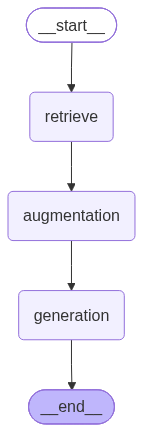

In [18]:
workflow

In [19]:
initial_state = {"query": input("Ask your question here: ")}
final_state = workflow.invoke(initial_state)
print(final_state['response'])

Increase the threshold (e.g., to 0.6) so fewer rephrases are triggered, and reduce maxretry (default 3) to 2 to save LLM calls. First change those values in the code, then tweak further by experimentation.
